In [ ]:
# Mount Google Drive

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

In [ ]:
df = pd.read_excel("/content/dataset.xlsx")

In [ ]:
df.head()

,description,path,category
0,"A photograph of a young man with short, tousle...","""G:\My Drive\photo\Photos\A_00382.jpg""",Real
1,A close-up photograph of a smiling young man w...,"""G:\My Drive\photo\Photos\A_00383.jpg""",Real
2,A photograph of a young man with short light b...,"""G:\My Drive\photo\Photos\A_00384.jpg""",Real
3,A portrait of a young man with neatly styled b...,"""G:\My Drive\photo\Photos\A_00385.jpg""",Real
4,A cheerful young woman wearing a wide-brimmed ...,"""G:\My Drive\photo\Photos\A_00386.jpg""",Real


In [ ]:
df.shape

(1200, 3)

In [ ]:
# ================================
# Import Required Libraries
# ================================

# Basic libraries
import os
import random
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
from PIL import Image

# Deep Learning - PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Torchvision (Image models and transforms)
import torchvision
from torchvision import transforms, models

# Transformer models (Text encoder)
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification
)

# Train-test split and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Progress bar
from tqdm.auto import tqdm

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")


# Check versions
print("Python libraries imported successfully")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Python libraries imported successfully
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Using device: cuda


In [ ]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns)

# Dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (1200, 3)

Columns:
Index(['description', 'path', 'category'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   description  1200 non-null   object
 1   path         1200 non-null   object
 2   category     1200 non-null   object
dtypes: object(3)
memory usage: 28.3+ KB


category
Real    700
Fake    500
Name: count, dtype: int64


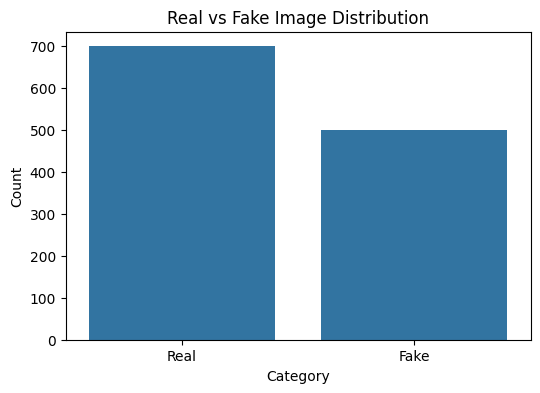

In [ ]:
# Check category distribution

print(df['category'].value_counts())

# Visualize class distribution

plt.figure(figsize=(6,4))
sns.countplot(
    data=df,
    x='category'
)

plt.title("Real vs Fake Image Distribution")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

In [ ]:
# =====================================
# Fix Image Paths for Google Colab
# =====================================

image_folder = "/content/drive/MyDrive/photo/Photos"

# Extract image filename from old Windows path
df['image_name'] = df['path'].apply(
    lambda x: os.path.basename(x.replace('"',''))
)

# Create new correct path
df['path'] = df['image_name'].apply(
    lambda x: os.path.join(image_folder, x)
)

# Check new paths
df[['image_name','path']].head()

,image_name,path
0,G:\My Drive\photo\Photos\A_00382.jpg,/content/drive/MyDrive/photo/Photos/G:\My Driv...
1,G:\My Drive\photo\Photos\A_00383.jpg,/content/drive/MyDrive/photo/Photos/G:\My Driv...
2,G:\My Drive\photo\Photos\A_00384.jpg,/content/drive/MyDrive/photo/Photos/G:\My Driv...
3,G:\My Drive\photo\Photos\A_00385.jpg,/content/drive/MyDrive/photo/Photos/G:\My Driv...
4,G:\My Drive\photo\Photos\A_00386.jpg,/content/drive/MyDrive/photo/Photos/G:\My Driv...


In [ ]:
# =====================================
# Correct Windows Path Extraction
# =====================================

import os

image_folder = "/content/drive/MyDrive/photo/Photos"

# Extract only filename from Windows path
df['image_name'] = df['path'].apply(
    lambda x: x.replace('"','').replace('\\','/').split('/')[-1]
)

# Create correct Google Drive path
df['path'] = df['image_name'].apply(
    lambda x: os.path.join(image_folder, x)
)

# Show result
df[['image_name','path']].head()

,image_name,path
0,A_00382.jpg,/content/drive/MyDrive/photo/Photos/A_00382.jpg
1,A_00383.jpg,/content/drive/MyDrive/photo/Photos/A_00383.jpg
2,A_00384.jpg,/content/drive/MyDrive/photo/Photos/A_00384.jpg
3,A_00385.jpg,/content/drive/MyDrive/photo/Photos/A_00385.jpg
4,A_00386.jpg,/content/drive/MyDrive/photo/Photos/A_00386.jpg


In [ ]:
df['image_exists'] = df['path'].apply(os.path.exists)

print(df['image_exists'].value_counts())

print("Missing images:", len(df[df['image_exists']==False]))

image_exists
True    1200
Name: count, dtype: int64
Missing images: 0


In [ ]:
# Show missing image information

missing = df[df['image_exists'] == False]

missing[['description', 'image_name', 'path', 'category']]

,description,image_name,path,category


In [ ]:
# =====================================
# Check Image Properties
# =====================================

from PIL import Image
import os

def get_image_info(path):
    try:
        img = Image.open(path)
        return pd.Series({
            "width": img.width,
            "height": img.height,
            "format": img.format
        })
    except:
        return pd.Series({
            "width": None,
            "height": None,
            "format": None
        })

image_info = df['path'].apply(get_image_info)

df = pd.concat([df, image_info], axis=1)

df.head()

,description,path,category,image_name,image_exists,width,height,format
0,"A photograph of a young man with short, tousle...",/content/drive/MyDrive/photo/Photos/A_00382.jpg,Real,A_00382.jpg,True,600,600,JPEG
1,A close-up photograph of a smiling young man w...,/content/drive/MyDrive/photo/Photos/A_00383.jpg,Real,A_00383.jpg,True,600,600,JPEG
2,A photograph of a young man with short light b...,/content/drive/MyDrive/photo/Photos/A_00384.jpg,Real,A_00384.jpg,True,600,600,JPEG
3,A portrait of a young man with neatly styled b...,/content/drive/MyDrive/photo/Photos/A_00385.jpg,Real,A_00385.jpg,True,600,600,JPEG
4,A cheerful young woman wearing a wide-brimmed ...,/content/drive/MyDrive/photo/Photos/A_00386.jpg,Real,A_00386.jpg,True,600,600,JPEG


In [ ]:
print("Image Resolution Summary:")
print(df[['width','height']].describe())

print("\nImage Formats:")
print(df['format'].value_counts())

Image Resolution Summary:
        width  height
count  1200.0  1200.0
mean    600.0   600.0
std       0.0     0.0
min     600.0   600.0
25%     600.0   600.0
50%     600.0   600.0
75%     600.0   600.0
max     600.0   600.0

Image Formats:
format
JPEG    1200
Name: count, dtype: int64


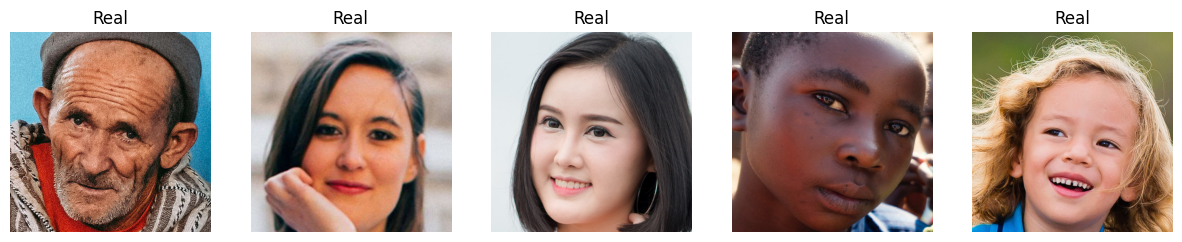

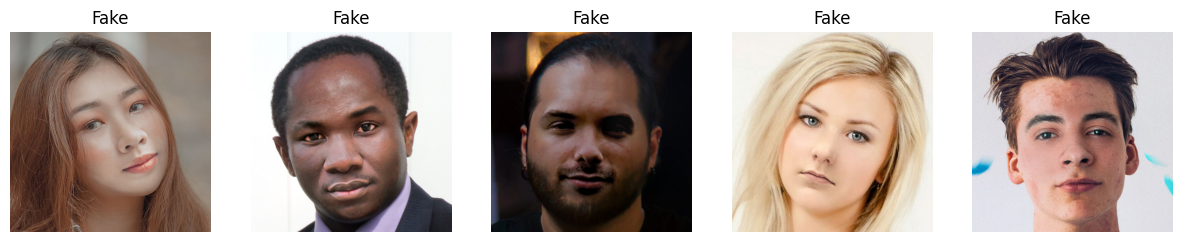

In [ ]:
# =====================================
# Visualize Samples
# =====================================

import matplotlib.pyplot as plt

def show_samples(label, n=5):

    samples = df[df['category']==label].sample(n)

    plt.figure(figsize=(15,5))

    for i, row in enumerate(samples.itertuples()):

        img = Image.open(row.path)

        plt.subplot(1,n,i+1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(label)

    plt.show()


# Real images
show_samples("Real",5)

# Fake images
show_samples("Fake",5)

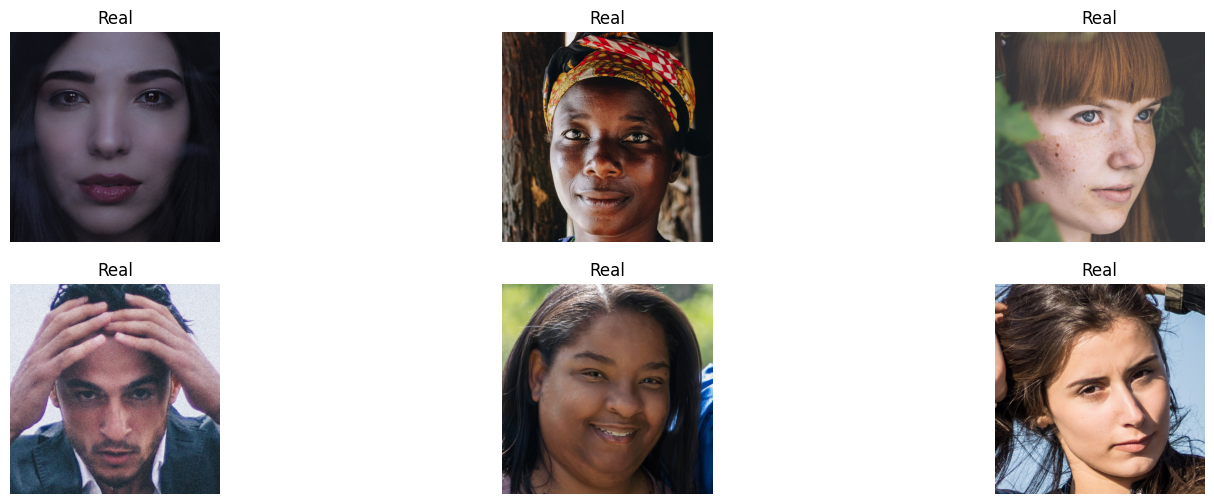

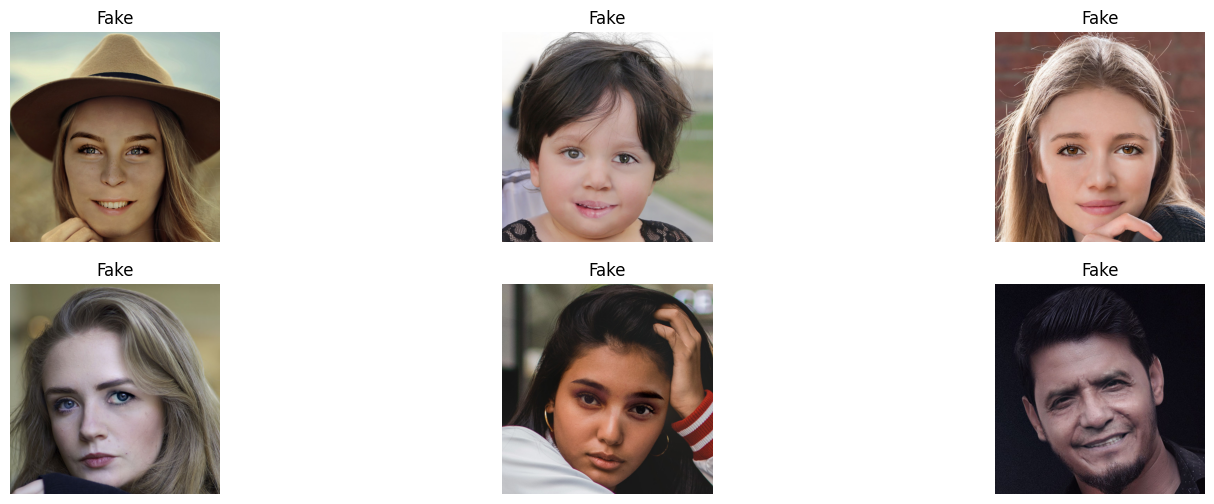

In [ ]:
# =====================================
# Display Real and Fake Samples
# =====================================

def display_samples(label, n=6):

    samples = df[df['category']==label].sample(n)

    plt.figure(figsize=(18,6))

    for i, row in enumerate(samples.itertuples()):

        img = Image.open(row.path)

        plt.subplot(2,3,i+1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(label)

    plt.show()


display_samples("Real",6)

display_samples("Fake",6)

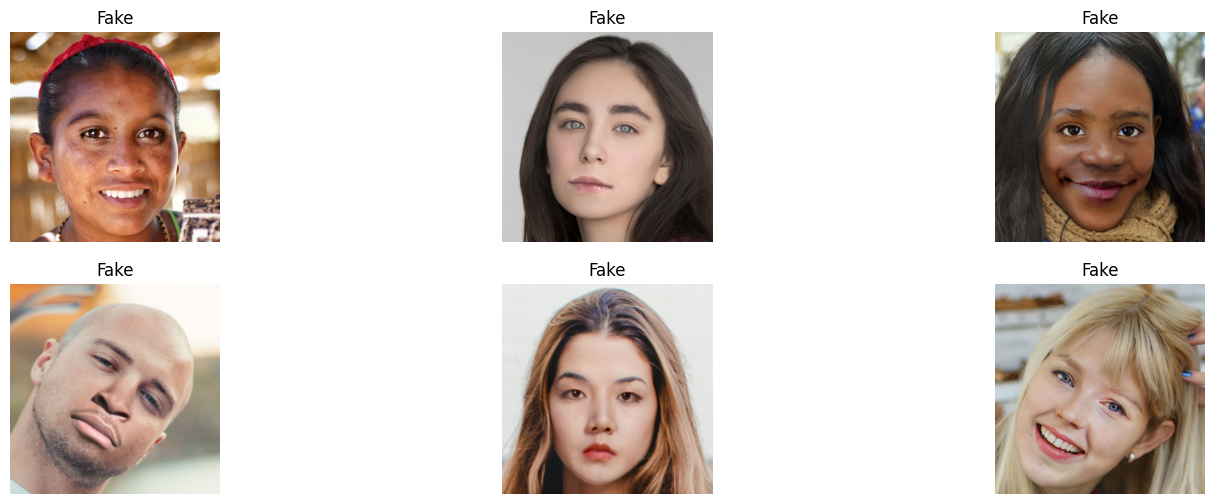

In [ ]:
display_samples("Fake",6)

count    1200.000000
mean       40.558333
std        16.786495
min         1.000000
25%        25.000000
50%        38.000000
75%        54.000000
max       104.000000
Name: text_length, dtype: float64


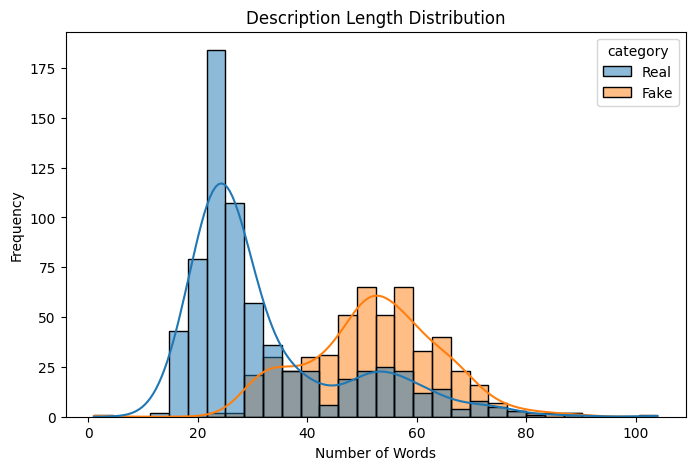

In [ ]:
# =========================================
# Text Length Analysis
# =========================================

df['text_length'] = df['description'].apply(
    lambda x: len(str(x).split())
)

print(df['text_length'].describe())


plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='text_length',
    hue='category',
    bins=30,
    kde=True
)

plt.title("Description Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Average words per class

df.groupby('category')['text_length'].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Fake,500.0,52.05,12.114496,1.0,45.0,52.0,60.00,90.0
Real,700.0,32.35,14.718885,13.0,23.0,27.0,37.25,104.0


In [ ]:
from collections import Counter

# Combine all text

all_words = " ".join(
    df['description'].astype(str)
).lower().split()


vocab = Counter(all_words)

print("Total words:", len(all_words))
print("Unique words:", len(vocab))


print("\nMost common words:")
print(vocab.most_common(20))

Total words: 48670
Unique words: 2004

Most common words:
[('a', 4151), ('with', 2158), ('the', 1634), ('and', 1535), ('her', 1158), ('hair', 921), ('young', 868), ('against', 673), ('at', 651), ('in', 650), ('dark', 601), ('woman', 578), ('camera', 568), ('his', 531), ('to', 499), ('brown', 494), ('an', 477), ('directly', 473), ('man', 427), ('gazes', 378)]


In [ ]:
# Separate classes

real_text = " ".join(
    df[df.category=="Real"]['description']
).lower().split()


fake_text = " ".join(
    df[df.category=="Fake"]['description']
).lower().split()


real_words = Counter(real_text)
fake_words = Counter(fake_text)


print("Real common words:")
print(real_words.most_common(20))


print("\nFake common words:")
print(fake_words.most_common(20))

Real common words:
[('a', 2185), ('with', 1065), ('and', 761), ('the', 693), ('young', 462), ('her', 431), ('hair', 429), ('against', 400), ('woman', 345), ('dark', 332), ('at', 299), ('camera', 294), ('man', 273), ('background.', 245), ('in', 235), ('wearing', 225), ('brown', 223), ('directly', 204), ('his', 190), ('an', 190)]

Fake common words:
[('a', 1966), ('with', 1093), ('the', 941), ('and', 774), ('her', 727), ('hair', 492), ('in', 415), ('young', 406), ('at', 352), ('his', 341), ('to', 332), ('an', 287), ('camera', 274), ('against', 273), ('brown', 271), ('directly', 269), ('dark', 269), ('styled', 248), ('on', 238), ('that', 234)]


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer


tfidf = TfidfVectorizer(
    max_features=1000,
    stop_words='english'
)


X = tfidf.fit_transform(df['description'])

features = tfidf.get_feature_names_out()

print("TF-IDF Shape:")
print(X.shape)

TF-IDF Shape:
(1200, 1000)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X = df[['text_length']]
y = df['category'].map({'Real':0,'Fake':1})

X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

model = LogisticRegression()

model.fit(X_train,y_train)

pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test,pred))

Accuracy: 0.7708333333333334


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Labels
y = df['category'].map({'Real':0, 'Fake':1})

# Split
X_train, X_test, y_train, y_test = train_test_split(
    df['description'],
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# TF-IDF
vectorizer = TfidfVectorizer(
    max_features=1000,
    stop_words='english'
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Logistic Regression
lr = LogisticRegression(
    max_iter=1000
)

lr.fit(X_train_tfidf, y_train)

pred = lr.predict(X_test_tfidf)

print("Accuracy:",
      accuracy_score(y_test,pred))

print(classification_report(y_test,pred))

Accuracy: 0.8416666666666667
              precision    recall  f1-score   support

           0       0.85      0.88      0.87       140
           1       0.82      0.79      0.81       100

    accuracy                           0.84       240
   macro avg       0.84      0.83      0.84       240
weighted avg       0.84      0.84      0.84       240



In [ ]:
# Get important words from TF-IDF Logistic Regression

feature_names = vectorizer.get_feature_names_out()

coefficients = lr.coef_[0]

important_words = pd.DataFrame({
    'word': feature_names,
    'importance': coefficients
})

print("Words indicating FAKE:")
display(
    important_words.sort_values(
        by='importance',
        ascending=False
    ).head(20)
)

print("Words indicating REAL:")
display(
    important_words.sort_values(
        by='importance',
        ascending=True
    ).head(20)
)

Words indicating FAKE:


,word,importance
850,stands,2.360941
448,highlights,2.039225
871,styled,1.957245
597,neutral,1.952189
976,waves,1.767358
535,loose,1.741192
980,wears,1.682917
59,backdrop,1.623634
657,person,1.474803
519,lighting,1.459526


Words indicating REAL:


,word,importance
534,looks,-2.599314
989,woman,-1.956396
169,close,-1.619854
662,photograph,-1.427313
694,portrait,-1.379727
882,sunlight,-1.181865
696,poses,-1.099053
834,softly,-1.098930
170,closed,-1.034405
344,facial,-1.030303


In [ ]:
!pip install -q sentence-transformers

In [ ]:
from sentence_transformers import SentenceTransformer

# Load pretrained sentence embedding model
text_encoder = SentenceTransformer(
    'all-MiniLM-L6-v2'
)

print("Sentence-BERT loaded successfully")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Sentence-BERT loaded successfully


In [ ]:
# Convert descriptions into embeddings

texts = df['description'].astype(str).tolist()

text_embeddings = text_encoder.encode(
    texts,
    batch_size=32,
    show_progress_bar=True
)

print("Embedding shape:", text_embeddings.shape)

Batches:   0%|          | 0/38 [00:00<?, ?it/s]

Embedding shape: (1200, 384)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


# Labels
y = df['category'].map({
    'Real':0,
    'Fake':1
})


# Split
X_train, X_test, y_train, y_test = train_test_split(
    text_embeddings,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


# Classifier
lr_sbert = LogisticRegression(
    max_iter=1000
)

lr_sbert.fit(
    X_train,
    y_train
)


# Prediction
pred = lr_sbert.predict(X_test)


print("Accuracy:",
      accuracy_score(y_test,pred))


print(classification_report(
    y_test,
    pred,
    target_names=['Real','Fake']
))

Accuracy: 0.8375
              precision    recall  f1-score   support

        Real       0.89      0.82      0.86       140
        Fake       0.77      0.86      0.82       100

    accuracy                           0.84       240
   macro avg       0.83      0.84      0.84       240
weighted avg       0.84      0.84      0.84       240



In [ ]:
!pip install -q open_clip_torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.8 MB/s eta 0:00:00


In [ ]:
import open_clip
import torch

model, _, preprocess = open_clip.create_model_and_transforms(
    'ViT-B-32',
    pretrained='openai'
)

tokenizer = open_clip.get_tokenizer(
    'ViT-B-32'
)

model = model.to(device)

print("CLIP loaded")

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

CLIP loaded


In [ ]:
texts = df['description'].tolist()

tokens = tokenizer(texts).to(device)

with torch.no_grad():
    text_features = model.encode_text(tokens)

text_features = text_features.cpu().numpy()

print(text_features.shape)

(1200, 512)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


# Labels
y = df['category'].map({
    'Real':0,
    'Fake':1
})


# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    text_features,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


# Classifier
lr_clip = LogisticRegression(
    max_iter=1000
)


lr_clip.fit(
    X_train,
    y_train
)


# Prediction
pred = lr_clip.predict(X_test)


print("Accuracy:",
      accuracy_score(y_test,pred))


print(classification_report(
    y_test,
    pred,
    target_names=['Real','Fake']
))

Accuracy: 0.8166666666666667
              precision    recall  f1-score   support

        Real       0.86      0.82      0.84       140
        Fake       0.76      0.81      0.79       100

    accuracy                           0.82       240
   macro avg       0.81      0.82      0.81       240
weighted avg       0.82      0.82      0.82       240



In [ ]:
# =====================================
# Load ResNet152 Feature Extractor
# =====================================

import torch
import torch.nn as nn
from torchvision import models, transforms


# Load pretrained ResNet152
resnet = models.resnet152(
    weights=models.ResNet152_Weights.IMAGENET1K_V2
)

# Remove classification layer
resnet = nn.Sequential(
    *list(resnet.children())[:-1]
)

# Move to GPU
resnet = resnet.to(device)

# Evaluation mode
resnet.eval()

print("ResNet152 feature extractor loaded")

Downloading: "https://download.pytorch.org/models/resnet152-f82ba261.pth" to /root/.cache/torch/hub/checkpoints/resnet152-f82ba261.pth


100%|██████████| 230M/230M [00:01<00:00, 171MB/s]


ResNet152 feature extractor loaded


In [ ]:
# =====================================
# Image preprocessing
# =====================================

image_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

print("Image transform ready")

Image transform ready


In [ ]:
# =====================================
# Generate ResNet image embeddings
# =====================================

def extract_image_embedding(path):

    image = Image.open(path).convert("RGB")

    image = image_transform(image)

    image = image.unsqueeze(0).to(device)

    with torch.no_grad():

        feature = resnet(image)

    feature = feature.squeeze()

    return feature.cpu().numpy()

In [ ]:
# =====================================
# Extract all image features
# =====================================

image_embeddings = []

for path in tqdm(df['path']):

    emb = extract_image_embedding(path)

    image_embeddings.append(emb)


image_embeddings = np.array(image_embeddings)


print("Image embedding shape:",
      image_embeddings.shape)

  0%|          | 0/1200 [00:00<?, ?it/s]

Image embedding shape: (1200, 2048)


In [ ]:
# =====================================
# Image embedding classification
# =====================================

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


# Labels
y = df['category'].map({
    'Real':0,
    'Fake':1
})


X_train, X_test, y_train, y_test = train_test_split(
    image_embeddings,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


image_lr = LogisticRegression(
    max_iter=1000
)


image_lr.fit(
    X_train,
    y_train
)


pred = image_lr.predict(X_test)


print("Accuracy:",
      accuracy_score(y_test,pred))


print(classification_report(
    y_test,
    pred,
    target_names=['Real','Fake']
))

Accuracy: 0.6291666666666667
              precision    recall  f1-score   support

        Real       0.68      0.70      0.69       140
        Fake       0.56      0.53      0.54       100

    accuracy                           0.63       240
   macro avg       0.62      0.61      0.62       240
weighted avg       0.63      0.63      0.63       240

